In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

RANDOM_STATE = 42
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 100)

In [2]:
PROJECT_DIR = Path(r"E:\DataMining_Group32")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train_processed.csv")
X_val = pd.read_csv(PROCESSED_DIR / "X_val_processed.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_processed.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")
y_val = pd.read_csv(PROCESSED_DIR / "y_val.csv").squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)

X_train: (70024, 38)
X_val: (14960, 38)
X_test: (15000, 38)
y_train: (70024,)


In [4]:
print("Missing values:")
print("Train:", X_train.isna().sum().sum())
print("Val:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

print("\nNumber of features:", X_train.shape[1])

print("\nClass distribution in train:")
display(y_train.value_counts(normalize=True).sort_index() * 100)

constant_features = [col for col in X_train.columns if X_train[col].nunique(dropna=False) == 1]
print("\nConstant features:", constant_features)

Missing values:
Train: 0
Val: 0
Test: 0

Number of features: 38

Class distribution in train:


__target__
1     0.848281
2    79.648406
3    16.797098
4     2.706215
Name: proportion, dtype: float64


Constant features: ['bool__f31', 'remainder__f12']


In [5]:
constant_features = [col for col in X_train.columns if X_train[col].nunique(dropna=False) == 1]
constant_features.append("f6__f6")
candidate_features = [col for col in X_train.columns if col not in constant_features]
print("\nNumber of candidate features:", len(candidate_features))


Number of candidate features: 35


In [6]:
X_train_fs = X_train[candidate_features].copy()
mi_scores = mutual_info_classif(
    X_train_fs,
    y_train,
    random_state=RANDOM_STATE,
    discrete_features=False
)

mi_series = pd.Series(mi_scores, index=X_train_fs.columns, name="mutual_info")
mi_series.sort_values(ascending=False).head(15)

remainder__f10                    0.117797
num_robust__duration_minutes      0.106730
remainder__f1                     0.097981
num_standard__f5                  0.087773
num_robust__f7                    0.087285
num_standard__f4                  0.071983
remainder__f8_is_highway          0.044971
remainder__f8_is_severe_crash     0.043503
remainder__f11                    0.032814
remainder__f9_is_highway_route    0.030701
num_robust__f15                   0.027531
remainder__f21                    0.023206
num_robust__f19                   0.022573
remainder__f8_is_local_road       0.018337
remainder__f18                    0.017760
Name: mutual_info, dtype: float64

In [7]:
f_scores, p_values = f_classif(X_train_fs, y_train)

f_series = pd.Series(f_scores, index=X_train_fs.columns, name="f_score")
f_series = f_series.replace([np.inf, -np.inf], np.nan).fillna(0)

p_series = pd.Series(p_values, index=X_train_fs.columns, name="p_value")
p_series = p_series.replace([np.inf, -np.inf], np.nan).fillna(1)

f_series.sort_values(ascending=False).head(15)

remainder__f1                     4616.917263
remainder__f10                    3988.466495
remainder__f8_is_highway          1598.148247
num_robust__duration_minutes      1370.784725
remainder__f9_is_highway_route    1343.031276
remainder__f8_is_severe_crash     1185.301114
remainder__f11                    1099.506360
remainder__f21                    1097.963697
num_robust__f7                     900.037039
remainder__f18                     790.882847
remainder__f8_is_slow_traffic      480.535837
bool__f23                          371.634516
bool__f30                          343.955066
remainder__f8_is_local_road        287.716747
num_standard__f4                   115.203512
Name: f_score, dtype: float64

In [8]:
tree_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

tree_model.fit(X_train_fs, y_train)

tree_series = pd.Series(
    tree_model.feature_importances_,
    index=X_train_fs.columns,
    name="extra_trees_importance"
)

tree_series.sort_values(ascending=False).head(15)

remainder__f1                     0.098892
remainder__f10                    0.078356
num_robust__duration_minutes      0.073985
num_robust__f7                    0.069948
cyclic__start_month               0.048072
remainder__f21                    0.046013
remainder__f8_is_highway          0.043598
remainder__f9_is_highway_route    0.041486
num_standard__f5                  0.040767
remainder__f18                    0.040220
remainder__f11                    0.036943
cyclic__start_hour                0.034417
num_standard__f4                  0.033436
remainder__f8_is_severe_crash     0.031593
num_robust__f15                   0.031456
Name: extra_trees_importance, dtype: float64

In [9]:
ranking_df = pd.DataFrame({
    "feature": X_train_fs.columns,
    "mutual_info": mi_series,
    "f_score": f_series,
    "p_value": p_series,
    "extra_trees_importance": tree_series,
}).reset_index(drop=True)

ranking_df["rank_mi"] = ranking_df["mutual_info"].rank(ascending=False, method="min")
ranking_df["rank_f"] = ranking_df["f_score"].rank(ascending=False, method="min")
ranking_df["rank_tree"] = ranking_df["extra_trees_importance"].rank(ascending=False, method="min")

ranking_df["mean_rank"] = ranking_df[["rank_mi", "rank_f", "rank_tree"]].mean(axis=1)

ranking_df = ranking_df.sort_values("mean_rank").reset_index(drop=True)
ranking_df["selected_top25"] = ranking_df.index < 25

ranking_df

,feature,mutual_info,f_score,p_value,extra_trees_importance,rank_mi,rank_f,rank_tree,mean_rank,selected_top25
0,remainder__f10,0.117797,3988.466495,0.000000e+00,0.078356,1.0,2.0,2.0,1.666667,True
1,remainder__f1,0.097981,4616.917263,0.000000e+00,0.098892,3.0,1.0,1.0,1.666667,True
2,num_robust__duration_minutes,0.106730,1370.784725,0.000000e+00,0.073985,2.0,4.0,3.0,3.000000,True
3,remainder__f8_is_highway,0.044971,1598.148247,0.000000e+00,0.043598,7.0,3.0,7.0,5.666667,True
4,num_robust__f7,0.087285,900.037039,0.000000e+00,0.069948,5.0,9.0,4.0,6.000000,True
5,remainder__f9_is_highway_route,0.030701,1343.031276,0.000000e+00,0.041486,10.0,5.0,8.0,7.666667,True
6,remainder__f21,0.023206,1097.963697,0.000000e+00,0.046013,12.0,8.0,6.0,8.666667,True
7,remainder__f11,0.032814,1099.506360,0.000000e+00,0.036943,9.0,7.0,11.0,9.000000,True
8,remainder__f8_is_severe_crash,0.043503,1185.301114,0.000000e+00,0.031593,8.0,6.0,14.0,9.333333,True
9,num_standard__f5,0.087773,99.758874,1.958369e-64,0.040767,4.0,16.0,9.0,9.666667,True


In [10]:
selected_features = ranking_df.loc[ranking_df["selected_top25"], "feature"].tolist()
removed_features = ranking_df.loc[~ranking_df["selected_top25"], "feature"].tolist()

print("Selected features:", len(selected_features))
for i, feature in enumerate(selected_features, 1):
    print(f"{i:02d}. {feature}")

print("\nRemoved features:", len(removed_features))
for feature in removed_features:
    print("-", feature)

Selected features: 25
01. remainder__f10
02. remainder__f1
03. num_robust__duration_minutes
04. remainder__f8_is_highway
05. num_robust__f7
06. remainder__f9_is_highway_route
07. remainder__f21
08. remainder__f11
09. remainder__f8_is_severe_crash
10. num_standard__f5
11. num_standard__f4
12. remainder__f18
13. num_robust__f15
14. remainder__f8_is_slow_traffic
15. remainder__f8_is_local_road
16. num_robust__f14
17. bool__f30
18. num_robust__f19
19. cyclic__start_month
20. bool__f23
21. cyclic__start_hour
22. remainder__f32
23. remainder__f33
24. remainder__f34
25. bool__f28

Removed features: 10
- num_standard__f16
- cyclic__start_dayofweek
- num_robust__f17
- bool__f27
- num_robust__f20
- bool__f22
- bool__f24
- bool__f25
- bool__f29
- bool__f26


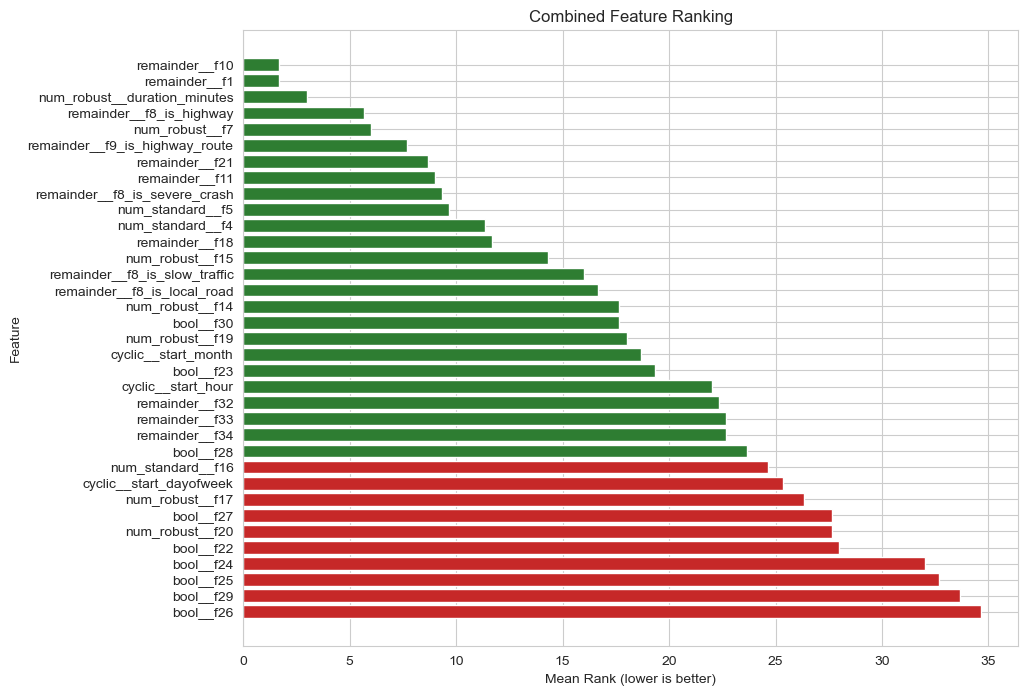

In [11]:
plt.figure(figsize=(10, 8))

plot_df = ranking_df.sort_values("mean_rank", ascending=True)

colors = plot_df["selected_top25"].map({True: "#2E7D32", False: "#C62828"})

plt.barh(plot_df["feature"], plot_df["mean_rank"], color=colors)
plt.gca().invert_yaxis()

plt.title("Combined Feature Ranking")
plt.xlabel("Mean Rank (lower is better)")
plt.ylabel("Feature")
plt.show()

In [12]:
X_train_selected = X_train[selected_features].copy()
X_val_selected = X_val[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

print("X_train_selected:", X_train_selected.shape)
print("X_val_selected:", X_val_selected.shape)
print("X_test_selected:", X_test_selected.shape)

print("\nSelected columns:")
print(X_train_selected.columns.tolist())

X_train_selected: (70024, 25)
X_val_selected: (14960, 25)
X_test_selected: (15000, 25)

Selected columns:
['remainder__f10', 'remainder__f1', 'num_robust__duration_minutes', 'remainder__f8_is_highway', 'num_robust__f7', 'remainder__f9_is_highway_route', 'remainder__f21', 'remainder__f11', 'remainder__f8_is_severe_crash', 'num_standard__f5', 'num_standard__f4', 'remainder__f18', 'num_robust__f15', 'remainder__f8_is_slow_traffic', 'remainder__f8_is_local_road', 'num_robust__f14', 'bool__f30', 'num_robust__f19', 'cyclic__start_month', 'bool__f23', 'cyclic__start_hour', 'remainder__f32', 'remainder__f33', 'remainder__f34', 'bool__f28']


مقایسه بین همه فیچر ها و 25 فیچر انتخاب شده

In [13]:
baseline_all = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

baseline_selected = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

baseline_all.fit(X_train_fs, y_train)
pred_all = baseline_all.predict(X_val[candidate_features])

baseline_selected.fit(X_train_selected, y_train)
pred_selected = baseline_selected.predict(X_val_selected)

comparison = pd.DataFrame({
    "feature_set": ["all_candidate_features", "selected_25_features"],
    "num_features": [len(candidate_features), len(selected_features)],
    "accuracy": [
        accuracy_score(y_val, pred_all),
        accuracy_score(y_val, pred_selected)
    ],
    "macro_f1": [
        f1_score(y_val, pred_all, average="macro"),
        f1_score(y_val, pred_selected, average="macro")
    ],
    "weighted_f1": [
        f1_score(y_val, pred_all, average="weighted"),
        f1_score(y_val, pred_selected, average="weighted")
    ]
})

comparison


,feature_set,num_features,accuracy,macro_f1,weighted_f1
0,all_candidate_features,35,0.820856,0.521309,0.831684
1,selected_25_features,25,0.823663,0.526565,0.834258


In [14]:
from sklearn.metrics import classification_report
print("Classification Report - Selected 25 Features")
print(classification_report(y_val, pred_selected))

Classification Report - Selected 25 Features
              precision    recall  f1-score   support

           1       0.26      0.50      0.34       127
           2       0.93      0.86      0.89     11915
           3       0.64      0.78      0.70      2513
           4       0.15      0.22      0.18       405

    accuracy                           0.82     14960
   macro avg       0.49      0.59      0.53     14960
weighted avg       0.85      0.82      0.83     14960



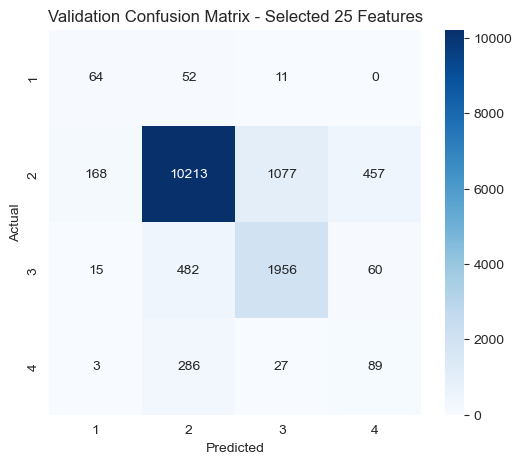

In [15]:
labels = sorted(y_train.unique())
cm = confusion_matrix(y_val, pred_selected, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Validation Confusion Matrix - Selected 25 Features")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [16]:
ranking_df.to_csv(OUTPUTS_DIR / "feature_selection_ranking.csv", index=False)
comparison.to_csv(OUTPUTS_DIR / "feature_selection_model_comparison.csv", index=False)

with open(MODELS_DIR / "selected_25_features.json", "w", encoding="utf-8") as f:
    json.dump(selected_features, f, indent=2)

X_train_selected.to_csv(PROCESSED_DIR / "X_train_selected_25.csv", index=False)
X_val_selected.to_csv(PROCESSED_DIR / "X_val_selected_25.csv", index=False)
X_test_selected.to_csv(PROCESSED_DIR / "X_test_selected_25.csv", index=False)



In [17]:
import sys

NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.append(str(NOTEBOOKS_DIR))

from custom_transformers import (
    PreprocessingPipelineWithDedup,
    DatetimeFeatureExtractor,
    BoolToInt,
    TargetEncoder,
    DayNightBinaryEncoder,
    IQRCapper,
    TextKeywordExtractor
)

def preprocess_and_select_25(raw_df):
    preprocess_pipeline = joblib.load(MODELS_DIR / "main_preprocess_pipeline.pkl")

    X_raw = raw_df.drop(columns=["y"], errors="ignore")

    X_processed = preprocess_pipeline.transform(X_raw)
    feature_names = preprocess_pipeline.named_steps["col_transformer"].get_feature_names_out()

    X_processed_df = pd.DataFrame(X_processed, columns=feature_names)

    with open(MODELS_DIR / "selected_25_features.json", "r", encoding="utf-8") as f:
        selected = json.load(f)

    return X_processed_df[selected].copy()

In [18]:
raw_df_sample = pd.read_csv(PROJECT_DIR / "data" / "raw" / "group_32_train.csv").sample(
    5,
    random_state=RANDOM_STATE
)

sample_selected = preprocess_and_select_25(raw_df_sample)

print(sample_selected.shape)
display(sample_selected)

(5, 25)


,remainder__f10,remainder__f1,num_robust__duration_minutes,remainder__f8_is_highway,num_robust__f7,remainder__f9_is_highway_route,remainder__f21,remainder__f11,remainder__f8_is_severe_crash,num_standard__f5,num_standard__f4,remainder__f18,num_robust__f15,remainder__f8_is_slow_traffic,remainder__f8_is_local_road,num_robust__f14,bool__f30,num_robust__f19,cyclic__start_month,bool__f23,cyclic__start_hour,remainder__f32,remainder__f33,remainder__f34,bool__f28
0,2.144971,2.331274,-0.322911,1.0,-0.064240,0.0,2.209149,2.179879,1.0,0.456485,0.005996,2.223254,0.000000,0.0,1.0,0.576923,0.0,0.22,0.545455,0.0,0.826087,1.0,1.0,1.0,0.0
1,2.243301,2.121822,-0.644205,1.0,2.435760,0.0,2.160241,2.227273,1.0,1.159418,0.799224,2.163777,0.684211,0.0,0.0,0.423077,0.0,1.20,0.363636,0.0,0.652174,1.0,1.0,1.0,0.0
2,1.983711,2.121822,0.075112,0.0,0.325482,0.0,2.134757,2.121397,0.0,-0.942201,-0.763821,2.224897,-0.842105,0.0,1.0,-0.538462,0.0,0.40,0.090909,0.0,0.304348,1.0,1.0,1.0,1.0
3,2.509723,2.121822,2.038005,0.0,-0.064240,0.0,2.363643,2.513887,1.0,0.628778,-0.738746,2.221028,0.000000,0.0,1.0,0.957692,0.0,1.14,0.454545,0.0,0.434783,1.0,1.0,1.0,0.0
4,2.097711,2.331274,-0.485894,0.0,-0.064240,0.0,2.390045,2.076010,1.0,-0.170575,-0.147849,2.217640,0.000000,0.0,1.0,0.423077,1.0,0.22,0.818182,1.0,0.347826,1.0,1.0,1.0,0.0


In [19]:
%%writefile inference_utils.py

import json
import joblib
import pandas as pd
from pathlib import Path

from custom_transformers import (
    PreprocessingPipelineWithDedup,
    DatetimeFeatureExtractor,
    BoolToInt,
    TargetEncoder,
    DayNightBinaryEncoder,
    IQRCapper,
    TextKeywordExtractor
)

def preprocess_and_select_25(raw_df, project_dir=None, y=None):
    """
    اگر y داده شود: روی حالت Train اجرا می‌شود (شامل Deduplication و بازگرداندن y_clean).
    اگر y داده نشود: روی حالت Val/Test اجرا می‌شود (فقط Transform بدون حذف سطر).
    """
    if project_dir is None:
        project_dir = Path(__file__).resolve().parents[1]
    else:
        project_dir = Path(project_dir)

    models_dir = project_dir / "models"

    pipeline_path = models_dir / "main_preprocess_pipeline.pkl"
    selected_features_path = models_dir / "selected_25_features.json"

    preprocess_pipeline = joblib.load(pipeline_path)

    X_raw = raw_df.drop(columns=["y"], errors="ignore")

    if y is not None:
        X_processed = preprocess_pipeline.fit_transform(X_raw, y)
        
        y_clean = preprocess_pipeline.y_clean_.reset_index(drop=True)
    else:
        X_processed = preprocess_pipeline.transform(X_raw)
        y_clean = None

    feature_names = preprocess_pipeline.named_steps["col_transformer"].get_feature_names_out()
    X_processed_df = pd.DataFrame(X_processed, columns=feature_names)

    with open(selected_features_path, "r", encoding="utf-8") as f:
        selected_features = json.load(f)

    X_selected = X_processed_df[selected_features].copy()

    if y_clean is not None:
        return X_selected, y_clean
        
    return X_selected

Overwriting inference_utils.py
